In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

### 1. Load Dataset & Initial Inspection

Load the Sales_transactions_2022_2025.csv dataset and inspect its dimensions and data types before cleaning.

In [31]:
df = pd.read_csv('Sales_transactions_2022_2025.csv')
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype(str).str.strip().str.title()
print(list(zip(df.columns, df.dtypes)))

[('Transaction_ID', <StringDtype(storage='python', na_value=nan)>), ('Order_ID', <StringDtype(storage='python', na_value=nan)>), ('Customer_ID', <StringDtype(storage='python', na_value=nan)>), ('Customer_Name', <StringDtype(storage='python', na_value=nan)>), ('Customer_Age', <StringDtype(storage='python', na_value=nan)>), ('Customer_Gender', <StringDtype(storage='python', na_value=nan)>), ('Customer_Segment', <StringDtype(storage='python', na_value=nan)>), ('Order_Date', <StringDtype(storage='python', na_value=nan)>), ('Order_Time', <StringDtype(storage='python', na_value=nan)>), ('Sales_Channel', <StringDtype(storage='python', na_value=nan)>), ('Store_ID', <StringDtype(storage='python', na_value=nan)>), ('Store_Name', <StringDtype(storage='python', na_value=nan)>), ('Country', <StringDtype(storage='python', na_value=nan)>), ('Region', <StringDtype(storage='python', na_value=nan)>), ('City', <StringDtype(storage='python', na_value=nan)>), ('Product_ID', <StringDtype(storage='python', n

### 2. Feature Selection & Data Leakage Prevention

Remove unique IDs (which cause overfitting) and post-purchase fields like Return_Reason and Order_Status so the model only learns from information available at the time of purchase.

In [32]:
target = 'Return_Flag'
drop_cols = [
    'Transaction_ID', 'Order_ID', 'Customer_ID', 'Customer_Name',
    'Store_ID', 'Product_ID', 'Sales_Representative',
    'Return_Reason', 'Order_Status', 'Customer_Rating', 'Sales_Amount',
    'Order_Date', 'Order_Time'
]
# Ensure Quantity is numeric first, then filter out non-positive quantities (refund/adjustment logs)
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df = df[df['Quantity'] > 0].copy()

X = df.drop(columns=[c for c in drop_cols + [target] if c in df.columns])
y = df[target]


### 3. Split the Data for Traning, Validating, and Testing (80% / 10% / 10%)

Split the dataset before any imputation or scaling to prevent data leakage, using stratification to preserve the return-to-non-return ratio across all three sets.

In [33]:
# Step 1: Split into 80% Train and 20% Temp (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Step 2: Split the 20% Temp set equally into 10% Validation and 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

print(df['Return_Flag'].value_counts(dropna=False))

Train shape: (14429, 22)
Validation shape: (1804, 22)
Test shape: (1804, 22)
Return_Flag
No     16160
Yes     1877
Name: count, dtype: int64


### 4. Numeric Type Casting & Target Encoding

Convert numeric fields stored as strings into true numeric types and map Return_Flag (True/False) into binary labels.

In [34]:
to_numeric = [
    'Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage',
    'Cost_Amount', 'Profit', 'Delivery_Days', 'Inventory_Level', 'Order_Year'
]

# Keep only the ones still present in X_train
num_cols = [col for col in to_numeric if col in X_train.columns]

# Convert strings to actual numbers
for col in num_cols:
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_val[col] = pd.to_numeric(X_val[col], errors='coerce')
    X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

target_map = {'yes': 1, 'no': 0, 'true': 1, 'false': 0, '1': 1, '0': 0}

y_train = y_train.astype(str).str.strip().str.lower().map(target_map)
y_val   = y_val.astype(str).str.strip().str.lower().map(target_map)
y_test  = y_test.astype(str).str.strip().str.lower().map(target_map)
print("Target class counts (y_train):")
print(y_train.value_counts(dropna=False))
print("\nTarget percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTarget class counts (y_val):")
print(y_val.value_counts(dropna=False))
print("\nTarget percentages:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTarget class counts (y_test):")
print(y_test.value_counts(dropna=False))
print("\nTarget percentages:")
print(y_test.value_counts(normalize=True) * 100)

Target class counts (y_train):
Return_Flag
0    12927
1     1502
Name: count, dtype: int64

Target percentages:
Return_Flag
0    89.590408
1    10.409592
Name: proportion, dtype: float64

Target class counts (y_val):
Return_Flag
0    1616
1     188
Name: count, dtype: int64

Target percentages:
Return_Flag
0    89.578714
1    10.421286
Name: proportion, dtype: float64

Target class counts (y_test):
Return_Flag
0    1617
1     187
Name: count, dtype: int64

Target percentages:
Return_Flag
0    89.634146
1    10.365854
Name: proportion, dtype: float64


### 5. Imputation, One-Hot Encoding & Feature Scaling

Fit a ColumnTransformer strictly on the training data to impute missing values, one-hot encode categorical text features, and standardize numeric features (required for Logistic Regression and our MLP neural network).

In [35]:
# Dynamically grab numeric vs. categorical columns from X_train
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

print("Numeric features:", num_features)
print("Categorical features:", cat_features)

# Numeric pipeline: Median imputation + Standard Scaling
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Constant imputation + One-Hot Encoding
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

# Fit ONLY on X_train, then transform all three splits!
X_train_ready = preprocessor.fit_transform(X_train)
X_val_ready = preprocessor.transform(X_val)
X_test_ready = preprocessor.transform(X_test)

print(f"Final Train matrix: {X_train_ready.shape}")
print(f"Final Val matrix:   {X_val_ready.shape}")
print(f"Final Test matrix:  {X_test_ready.shape}")

display(X_train[num_cols].describe().round(2))

Numeric features: ['Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Cost_Amount', 'Profit', 'Delivery_Days', 'Inventory_Level', 'Order_Year']
Categorical features: ['Customer_Gender', 'Customer_Segment', 'Sales_Channel', 'Store_Name', 'Country', 'Region', 'City', 'Product_Name', 'Product_Category', 'Product_Subcategory', 'Payment_Method', 'Shipping_Method', 'Promotion_Code']


Final Train matrix: (14429, 140)
Final Val matrix:   (1804, 140)
Final Test matrix:  (1804, 140)


,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Cost_Amount,Profit,Delivery_Days,Inventory_Level,Order_Year
count,14252.00,14429.00,14429.00,14429.00,14429.00,14429.00,14308.00,14269.00,14429.00
mean,38.98,2.12,232.50,6.25,363.22,91.18,2.25,70.29,2023.57
std,10.78,1.78,292.99,6.90,697.89,168.64,2.31,22.06,1.12
min,18.00,1.00,21.39,0.00,12.17,-299.31,0.00,0.00,2022.00
25%,31.00,1.00,52.28,0.00,56.42,19.41,0.00,55.00,2023.00
50%,39.00,2.00,100.13,5.00,122.76,40.27,1.00,70.00,2024.00
75%,46.00,3.00,287.22,10.00,374.11,92.81,4.00,85.00,2025.00
max,112.00,11.00,1425.09,110.00,10791.00,3512.08,10.00,157.00,2025.00


## Exploratory Data Analysis (Training Set)

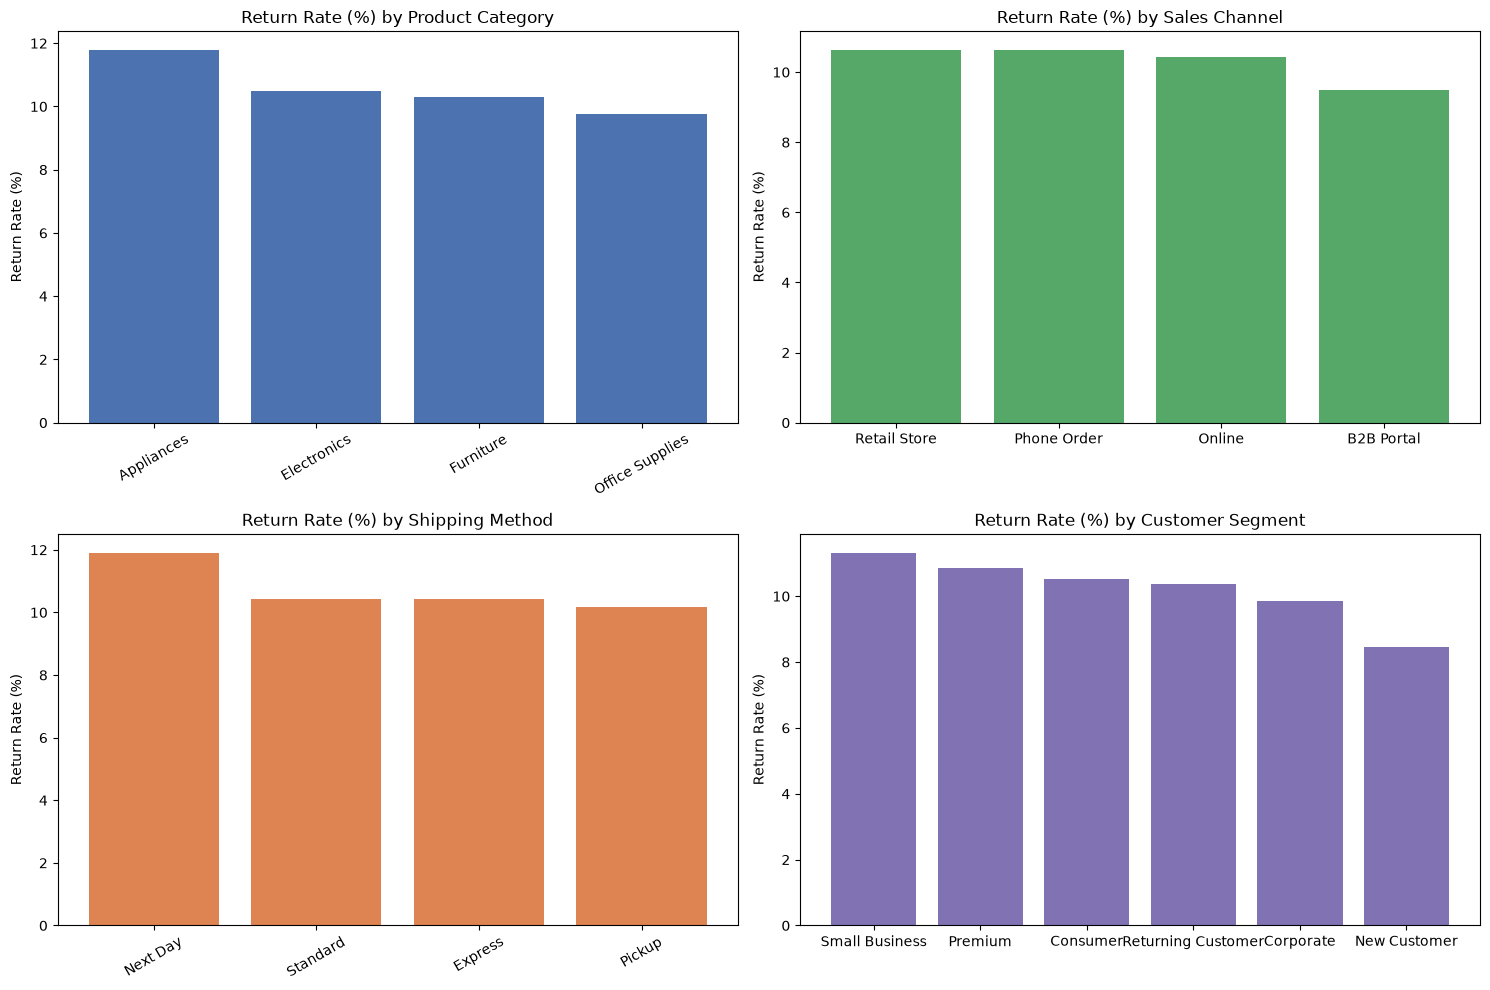

In [36]:
# Combine X_train and y_train temporarily for leak-free EDA
eda_df = X_train.copy()
eda_df['Return_Flag'] = y_train

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Return Rate by Product Category
cat_rates = eda_df.groupby('Product_Category')['Return_Flag'].mean().sort_values(ascending=False) * 100
axes[0, 0].bar(cat_rates.index, cat_rates.values, color='#4C72B0')
axes[0, 0].set_title('Return Rate (%) by Product Category')
axes[0, 0].set_ylabel('Return Rate (%)')
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Return Rate by Sales Channel
channel_rates = eda_df.groupby('Sales_Channel')['Return_Flag'].mean().sort_values(ascending=False) * 100
axes[0, 1].bar(channel_rates.index, channel_rates.values, color='#55A868')
axes[0, 1].set_title('Return Rate (%) by Sales Channel')
axes[0, 1].set_ylabel('Return Rate (%)')

# 3. Return Rate by Shipping Method
ship_rates = eda_df.groupby('Shipping_Method')['Return_Flag'].mean().sort_values(ascending=False) * 100
axes[1, 0].bar(ship_rates.index, ship_rates.values, color='#DD8452')
axes[1, 0].set_title('Return Rate (%) by Shipping Method')
axes[1, 0].set_ylabel('Return Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Return Rate by Customer Segment
seg_rates = eda_df.groupby('Customer_Segment')['Return_Flag'].mean().sort_values(ascending=False) * 100
axes[1, 1].bar(seg_rates.index, seg_rates.values, color='#8172B3')
axes[1, 1].set_title('Return Rate (%) by Customer Segment')
axes[1, 1].set_ylabel('Return Rate (%)')

plt.tight_layout()
plt.show()

## 7. Baseline Modeling (Logistic Regression & Random Forest)

In [37]:
def evaluate_model(name, model, X_val, y_val):
    # Generate binary predictions (0 or 1) and return probabilities
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]
    
    # Extract confusion matrix components: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
    
    # Proposal Metrics
    returned_detection_rate = tp / (tp + fn)      # Sensitivity / Recall (Class 1)
    non_returned_detection_rate = tn / (tn + fp)  # Specificity (Class 0)
    roc_auc = roc_auc_score(y_val, y_prob)
    
    print(f"=== {name} (Validation Set) ===")
    print(f"Returned Detection Rate (Recall):        {returned_detection_rate:.2%}")
    print(f"Non-Returned Detection Rate (Specificity): {non_returned_detection_rate:.2%}")
    print(f"ROC-AUC Score:                           {roc_auc:.4f}\n")

# 1. Train Logistic Regression Baseline
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_ready, y_train)
evaluate_model("Logistic Regression", log_reg, X_val_ready, y_val)

# 2. Train Random Forest Baseline
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,              # Prevents trees from memorizing training noise
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_ready, y_train)
evaluate_model("Random Forest", rf_model, X_val_ready, y_val)

=== Logistic Regression (Validation Set) ===
Returned Detection Rate (Recall):        51.60%
Non-Returned Detection Rate (Specificity): 54.21%
ROC-AUC Score:                           0.5220

=== Random Forest (Validation Set) ===
Returned Detection Rate (Recall):        13.30%
Non-Returned Detection Rate (Specificity): 85.95%
ROC-AUC Score:                           0.5173

